<a href="https://colab.research.google.com/github/james-mawuena/credit-card-fraud-detection/blob/main/credit_card_fraud_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
from sklearn.datasets import fetch_openml

data = fetch_openml(data_id=1597, as_frame=True)
df = data.frame
df["Class"] = df["Class"].astype(int)

print(df.shape)
print(df["Class"].value_counts())
df.head()

(284807, 30)
Class
0    284315
1       492
Name: count, dtype: int64


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training transactions:", len(y_train), "| frauds:", y_train.sum())
print("Test transactions:", len(y_test), "| frauds:", y_test.sum())

Training transactions: 227845 | frauds: 394
Test transactions: 56962 | frauds: 98


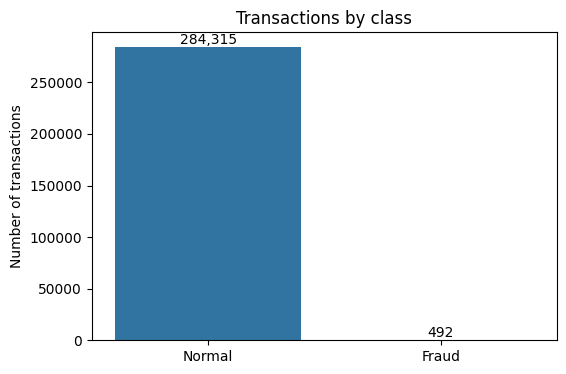

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=["Normal", "Fraud"], y=counts.values)
ax.bar_label(ax.containers[0], labels=[f"{v:,}" for v in counts.values])
plt.title("Transactions by class")
plt.ylabel("Number of transactions")
plt.show()

In [6]:
from sklearn.metrics import accuracy_score, recall_score

lazy = [0] * len(y_test)

print("Lazy guess accuracy:", round(accuracy_score(y_test, lazy), 4))
print("Frauds caught (recall):", recall_score(y_test, lazy))

Lazy guess accuracy: 0.9983
Frauds caught (recall): 0.0


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = scaler.transform(X_test[["Amount"]])

print(X_train["Amount"].describe().round(2))

count    227845.00
mean         -0.00
std           1.00
min          -0.35
25%          -0.33
50%          -0.26
75%          -0.04
max         102.12
Name: Amount, dtype: float64


## Logistic Regression

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score

log = LogisticRegression(max_iter=1000)
log.fit(X_train, y_train)
pred = log.predict(X_test)

print(confusion_matrix(y_test, pred))
print("Recall (frauds caught):", round(recall_score(y_test, pred), 3))
print("Precision (flags that were real fraud):", round(precision_score(y_test, pred), 3))

[[56851    13]
 [   35    63]]
Recall (frauds caught): 0.643
Precision (flags that were real fraud): 0.829


In [9]:
log_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
log_bal.fit(X_train, y_train)
pred_bal = log_bal.predict(X_test)

print(confusion_matrix(y_test, pred_bal))
print("Recall (frauds caught):", round(recall_score(y_test, pred_bal), 3))
print("Precision (flags that were real fraud):", round(precision_score(y_test, pred_bal), 3))

[[55425  1439]
 [    8    90]]
Recall (frauds caught): 0.918
Precision (flags that were real fraud): 0.059


## Neural Network

In [10]:
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

nn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
nn.compile(loss="binary_crossentropy", optimizer="adam")

n_normal = (y_train == 0).sum()
n_fraud = (y_train == 1).sum()
weights = {
    0: len(y_train) / (2 * n_normal),
    1: len(y_train) / (2 * n_fraud),
}

nn.fit(X_train, y_train, epochs=10, batch_size=2048,
       class_weight=weights, verbose=0)

pred_nn = (nn.predict(X_test, verbose=0).ravel() > 0.5).astype(int)

print(confusion_matrix(y_test, pred_nn))
print("Recall (frauds caught):", round(recall_score(y_test, pred_nn), 3))
print("Precision (flags that were real fraud):", round(precision_score(y_test, pred_nn), 3))

[[55747  1117]
 [    9    89]]
Recall (frauds caught): 0.908
Precision (flags that were real fraud): 0.074


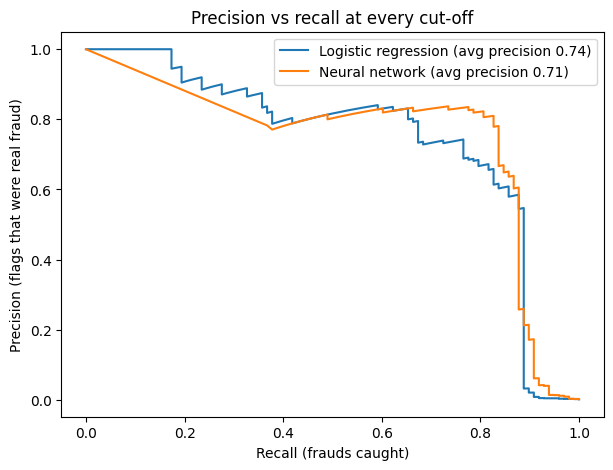

In [11]:
from sklearn.metrics import precision_recall_curve, average_precision_score

scores = {
    "Logistic regression": log.predict_proba(X_test)[:, 1],
    "Neural network": nn.predict(X_test, verbose=0).ravel(),
}

plt.figure(figsize=(7, 5))
for name, s in scores.items():
    precision, recall, _ = precision_recall_curve(y_test, s)
    ap = average_precision_score(y_test, s)
    plt.plot(recall, precision, label=f"{name} (avg precision {ap:.2f})")

plt.xlabel("Recall (frauds caught)")
plt.ylabel("Precision (flags that were real fraud)")
plt.title("Precision vs recall at every cut-off")
plt.legend()
plt.show()

In [12]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

print("Fit group:", len(y_fit), "| frauds:", y_fit.sum())
print("Validation group:", len(y_val), "| frauds:", y_val.sum())
print("Test group (untouched):", len(y_test), "| frauds:", y_test.sum())

Fit group: 170883 | frauds: 295
Validation group: 56962 | frauds: 99
Test group (untouched): 56962 | frauds: 98


## Logistic Regression with training, validation and test set

In [13]:
import numpy as np
from sklearn.metrics import precision_recall_curve

log2 = LogisticRegression(max_iter=1000)
log2.fit(X_fit, y_fit)

val_scores = log2.predict_proba(X_val)[:, 1]
precision, recall, cutoffs = precision_recall_curve(y_val, val_scores)
precision, recall = precision[:-1], recall[:-1]

ok = np.where(precision >= 0.5)[0]
best = ok[np.argmax(recall[ok])]
cutoff = cutoffs[best]

print("Chosen cut-off:", round(cutoff, 3))
print("Validation recall:", round(recall[best], 3))
print("Validation precision:", round(precision[best], 3))

Chosen cut-off: 0.013
Validation recall: 0.808
Validation precision: 0.5


In [14]:
test_scores = log2.predict_proba(X_test)[:, 1]
pred_cut = (test_scores >= cutoff).astype(int)

print(confusion_matrix(y_test, pred_cut))
print("Recall (frauds caught):", round(recall_score(y_test, pred_cut), 3))
print("Precision (flags that were real fraud):", round(precision_score(y_test, pred_cut), 3))

[[56762   102]
 [   12    86]]
Recall (frauds caught): 0.878
Precision (flags that were real fraud): 0.457


In [15]:
tf.keras.utils.set_random_seed(42)

nn2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_fit.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
nn2.compile(loss="binary_crossentropy", optimizer="adam")

n_normal = (y_fit == 0).sum()
n_fraud = (y_fit == 1).sum()
weights2 = {
    0: len(y_fit) / (2 * n_normal),
    1: len(y_fit) / (2 * n_fraud),
}
nn2.fit(X_fit, y_fit, epochs=10, batch_size=2048,
        class_weight=weights2, verbose=0)

val_nn = nn2.predict(X_val, verbose=0).ravel()
precision, recall, cutoffs = precision_recall_curve(y_val, val_nn)
precision, recall = precision[:-1], recall[:-1]
ok = np.where(precision >= 0.5)[0]
best = ok[np.argmax(recall[ok])]
cutoff_nn = cutoffs[best]

print("Chosen cut-off:", round(cutoff_nn, 3))
print("Validation recall:", round(recall[best], 3))
print("Validation precision:", round(precision[best], 3))

test_nn = nn2.predict(X_test, verbose=0).ravel()
pred_nn_cut = (test_nn >= cutoff_nn).astype(int)
print(confusion_matrix(y_test, pred_nn_cut))
print("Test recall:", round(recall_score(y_test, pred_nn_cut), 3))
print("Test precision:", round(precision_score(y_test, pred_nn_cut), 3))

Chosen cut-off: 0.922
Validation recall: 0.838
Validation precision: 0.5
[[56763   101]
 [   12    86]]
Test recall: 0.878
Test precision: 0.46


In [16]:
from sklearn.metrics import average_precision_score

results = []
for lr in [0.0001, 0.001, 0.01, 0.1]:
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_fit.shape[1],)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(loss="binary_crossentropy",
                  optimizer=tf.keras.optimizers.Adam(learning_rate=lr))
    history = model.fit(X_fit, y_fit, epochs=10, batch_size=2048,
                        class_weight=weights2, verbose=0)
    v_scores = model.predict(X_val, verbose=0).ravel()
    results.append({
        "Learning rate": lr,
        "Final training loss": round(history.history["loss"][-1], 4),
        "Validation avg precision": round(average_precision_score(y_val, v_scores), 3),
    })

pd.DataFrame(results)

,Learning rate,Final training loss,Validation avg precision
0,0.0001,0.2674,0.572
1,0.0010,0.0769,0.693
2,0.0100,0.0395,0.689
3,0.1000,0.2157,0.644
